# 1. Initial data exploration
Place the supplied files as described in `data/README.md` before running. Record actual findings here as the project progresses; no data is bundled.

In [1]:
from pathlib import Path
from bayesian_bbo import FUNCTION_SPECS, load_observations

# root = Path('../data')
# for function_id, dimension in FUNCTION_SPECS.items():
#     observations = load_observations(root, function_id)
#     print(f'Function {function_id}: {len(observations.inputs)} observations, {dimension} dimensions, best observed output {observations.best_output}')

## Notes to fill in after inspecting actual observations
Check ranges, repeated measurements, scale, provenance, and any quality issues before selecting models. Do not interpret unobserved objective behaviour.

Function 1: n=10.0, d=2.0, y_range=[-0.004, 0.000]


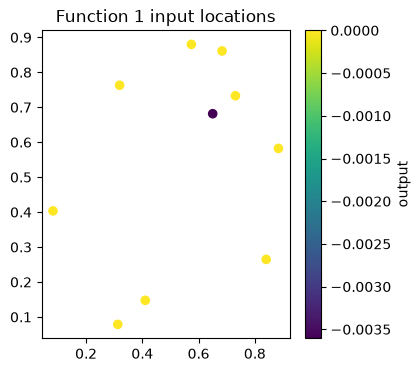

Function 2: n=10.0, d=2.0, y_range=[-0.066, 0.611]


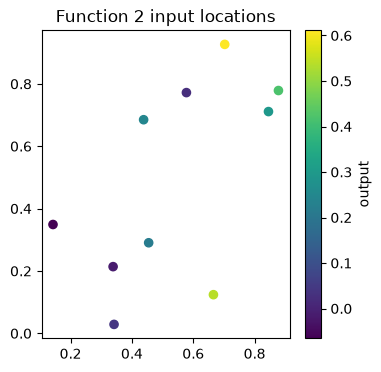

Function 3: n=15.0, d=3.0, y_range=[-0.399, -0.035]
  best point: [0.49258141 0.61159319 0.34017639]
  best output: -0.034835
Function 4: n=30.0, d=4.0, y_range=[-32.626, -4.026]
  best point: [0.57776561 0.42877174 0.42582587 0.24900741]
  best output: -4.025542
Function 5: n=20.0, d=4.0, y_range=[0.113, 1088.860]
  best point: [0.22418902 0.84648049 0.87948418 0.87851568]
  best output: 1088.859618
Function 6: n=20.0, d=5.0, y_range=[-2.571, -0.714]
  best point: [0.7281861  0.15469257 0.73255167 0.69399651 0.05640131]
  best output: -0.714265
Function 7: n=30.0, d=6.0, y_range=[0.003, 1.365]
  best point: [0.05789554 0.49167222 0.24742222 0.21811844 0.42042833 0.73096984]
  best output: 1.364968
Function 8: n=40.0, d=8.0, y_range=[5.592, 9.598]
  best point: [0.05644741 0.06595555 0.02292868 0.03878647 0.40393544 0.80105533
 0.48830701 0.89308498]
  best output: 9.598482


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path('../data')
rows = []
for folder in sorted(root.glob('function_*')):
    x = np.load(folder / 'initial_inputs.npy', allow_pickle=False)
    y = np.load(folder / 'initial_outputs.npy', allow_pickle=False)
    rows.append({
        'function': int(folder.name.split('_')[-1]),
        'n': int(x.shape[0]),
        'dimension': int(x.shape[1]),
        'x_min': float(np.min(x)),
        'x_max': float(np.max(x)),
        'y_min': float(np.min(y)),
        'y_max': float(np.max(y)),
        'best_y': float(np.max(y)),
    })

summary = pd.DataFrame(rows).sort_values('function').set_index('function')
summary

for fid, row in summary.iterrows():
    folder = root / f'function_{fid}'
    x = np.load(folder / 'initial_inputs.npy', allow_pickle=False)
    y = np.load(folder / 'initial_outputs.npy', allow_pickle=False)
    print(f'Function {fid}: n={row["n"]}, d={row["dimension"]}, y_range=[{row["y_min"]:.3f}, {row["y_max"]:.3f}]')
    if x.shape[1] == 2:
        fig, ax = plt.subplots(figsize=(4, 4))
        sc = ax.scatter(x[:, 0], x[:, 1], c=y, cmap='viridis', s=35)
        ax.set_title(f'Function {fid} input locations')
        fig.colorbar(sc, ax=ax, label='output')
        plt.show()
    else:
        best_idx = int(np.argmax(y))
        print(f'  best point: {x[best_idx]}')
        print(f'  best output: {y[best_idx]:.6f}')

In [5]:
x

array([[0.60499445, 0.29221502, 0.90845275, 0.35550624, 0.20166872,
        0.57533801, 0.31031095, 0.73428138],
       [0.17800696, 0.56622265, 0.99486184, 0.21032501, 0.32015266,
        0.70790879, 0.63538449, 0.10713163],
       [0.00907698, 0.81162615, 0.52052036, 0.07568668, 0.26511183,
        0.09165169, 0.59241515, 0.36732026],
       [0.50602816, 0.65373012, 0.36341078, 0.17798105, 0.0937283 ,
        0.19742533, 0.7558269 , 0.29247234],
       [0.35990926, 0.24907568, 0.49599717, 0.70921498, 0.11498719,
        0.28920692, 0.55729515, 0.59388173],
       [0.77881834, 0.0034195 , 0.33798313, 0.51952778, 0.82090699,
        0.53724669, 0.5513471 , 0.66003209],
       [0.90864932, 0.0622497 , 0.23825955, 0.76660355, 0.13233596,
        0.99024381, 0.68806782, 0.74249594],
       [0.58637144, 0.88073573, 0.74502075, 0.54603485, 0.00964888,
        0.74899176, 0.23090707, 0.09791562],
       [0.76113733, 0.85467239, 0.38212433, 0.33735198, 0.68970832,
        0.30985305, 0.631379